# Week 2: Exploratory Data Analysis & Outlier Detection
Final-Year B.Tech IT Project | AI-Based Resume Screening System

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
df = pd.read_csv('../data/raw_resumes.csv')
print('Loaded raw resumes dataset:')
print('Shape:', df.shape)
df.head(3)

Loaded raw resumes dataset:
Shape: (1020, 9)


,Candidate_ID,Resume_Text,Skills,Experience_Years,Education,CGPA,Projects_Count,Job_Role,Shortlisted
0,CID_1001,Passionate Data Scientist professional with B....,"Video Editing, sql, machine learning",1.7,B.Tech,6.96,4,Data Scientist,0
1,CID_1002,Passionate Software Engineer professional with...,"c++, algorithms, sql, oop, java, data structur...",6.4,B.Tech,9.15,7,Software Engineer,1
2,CID_1003,Passionate Python Developer professional with ...,"rest apis, django, docker, sql, flask, python,...",8.1,B.Tech,9.18,7,Python Developer,1


### 1. Missing Value Audit
Identify missing values across all resume columns.

In [2]:
# Missing values calculation
null_counts = df.isnull().sum()
null_pct = (null_counts / len(df)) * 100
missing_df = pd.DataFrame({'Missing_Count': null_counts, 'Missing_Percentage': null_pct.round(2)})
print('=== MISSING VALUE REPORT ===')
display(missing_df[missing_df['Missing_Count'] > 0])

=== MISSING VALUE REPORT ===


,Missing_Count,Missing_Percentage
Skills,30,2.94
Experience_Years,30,2.94
Education,30,2.94
CGPA,31,3.04


### 2. Outlier Detection: IQR & Z-score
Detect anomalous entries in Experience, CGPA, and Projects.

In [3]:
# IQR and Z-score outlier detection functions
def find_outliers_iqr(series, k=1.5):
    q25, q75 = series.quantile(0.25), series.quantile(0.75)
    iqr = q75 - q25
    low, high = q25 - k * iqr, q75 + k * iqr
    return (series < low) | (series > high), low, high

def find_outliers_zscore(series, threshold=3.0):
    mean, std = series.mean(), series.std()
    z = (series - mean) / std
    return z.abs() > threshold

num_cols = ['Experience_Years', 'CGPA', 'Projects_Count']
for col in num_cols:
    s = df[col].dropna()
    iqr_mask, low, high = find_outliers_iqr(s, k=1.5)
    z_mask = find_outliers_zscore(s, threshold=3.0)
    print(f'{col}:')
    print(f'  IQR (k=1.5) Outliers: {iqr_mask.sum()} [{low:.2f} to {high:.2f}]')
    print(f'  Z-score (|z|>3) Outliers: {z_mask.sum()}')

Experience_Years:
  IQR (k=1.5) Outliers: 2 [-2.95 to 11.05]
  Z-score (|z|>3) Outliers: 2
CGPA:
  IQR (k=1.5) Outliers: 2 [4.83 to 10.88]
  Z-score (|z|>3) Outliers: 2
Projects_Count:
  IQR (k=1.5) Outliers: 2 [-2.50 to 9.50]
  Z-score (|z|>3) Outliers: 2


### 3. Distribution Visualizations
Plot distributions of numerical features and job roles.

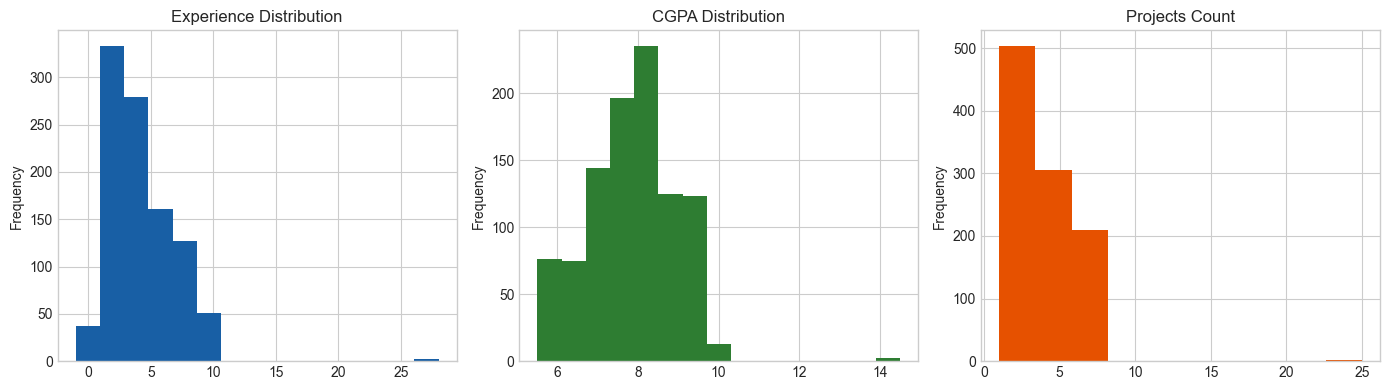

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
df['Experience_Years'].dropna().plot(kind='hist', bins=15, ax=axes[0], color='#185FA5', title='Experience Distribution')
df['CGPA'].dropna().plot(kind='hist', bins=15, ax=axes[1], color='#2E7D32', title='CGPA Distribution')
df['Projects_Count'].dropna().plot(kind='hist', bins=10, ax=axes[2], color='#E65100', title='Projects Count')
plt.tight_layout()
plt.show()

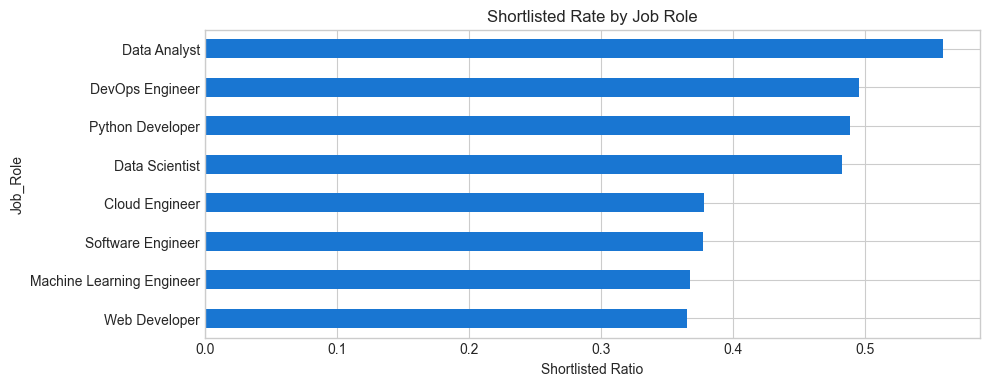

In [5]:
# Job Role vs Shortlisting percentage
plt.figure(figsize=(10, 4))
df.groupby('Job_Role')['Shortlisted'].mean().sort_values().plot(kind='barh', color='#1976D2')
plt.title('Shortlisted Rate by Job Role')
plt.xlabel('Shortlisted Ratio')
plt.show()